<a href="https://colab.research.google.com/github/mayajdias/walmart-hurricane-project/blob/main/notebooks/2026_10_28_midterm_clinic_analysis_and_charts_studio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Clinic Analysis and Charts

**Studio — 2026-10-28 · Fall 2026**  
**Class time:** 45 minutes

---

## Clinic — analysis and charts

Working session on your own project. The patterns below are the four analytical moves Questions 1 through 4 need; adapt each one to your cleaned data.

By the end of the hour you should have at least two charts you would be willing to put in the presentation on Monday.

In [ ]:
import os
if not os.path.exists('walmart-hurricane-project'):
    !git clone -q https://github.com/mayajdias/walmart-hurricane-project.git
DATA = 'walmart-hurricane-project/data/'
print(sorted(os.listdir(DATA)))

['distribution_centers.csv', 'inventory_and_sales.db', 'product_catalog (1).csv', 'store_locations.csv', 'walmart_transactions.csv']


In [ ]:
import pandas as pd, numpy as np, sqlite3

canonical_sku_groups = {
    'POPTART-STRAW': ['PT-12', 'SKU#459812', 'PT_STRAWBERRY'],
    'SOUP-CAN': ['CNSOUP-01'], 'BG-MONO': ['GAME-MONO', 'MONOPOLY-01'],
    'BEER-24': ['LTBEER24'], 'WTR-24': ['WTR_24PK', 'WATER24PK'],
    'CANDLE-EMRG': ['CNDL-EM'], 'TARP-HD': ['HDTARP-01'], 'LED-FLASH': ['FLASH-01'],
    'CHRG-PORT': ['PORTCHARGER'], 'FIRSTAID-KIT': ['FAID-01'], 'ROKU-STD': ['STREAM-01'],
    'PTOWEL-6': ['PAPERTOWEL6'], 'PLAYCARD-STD': ['CARDS-01'], 'BREAD-WH': ['WHITEBREAD'],
    'TOILETPAPER12': ['TP-12'], 'PNUTBTR-16': ['PB-16'], 'BABYFORMULA': ['BFORM-01'],
    'DIAPERS-3': ['DIAP-S3'], 'BAT-AA4': ['BATT-100', 'BATT_AA_4PK'], 'CHIPVARIETY': ['CHIPS-VP'],
}
sku_mapping = {o: t for t, os_ in canonical_sku_groups.items() for o in os_}

canonical_category_groups = {
    'Emergency': ['EMERGENCY', 'Emergency Supplies', 'emergency'],
    'Grocery': ['Groceries', 'grocery', 'GROCERY'],
    'Electronics': ['electronics', 'ELECTRONICS'],
    'Entertainment': ['Games & Entertainment', 'entertainment', 'ENTERTAINMENT'],
    'Household': ['HOUSEHOLD', 'household', 'Household Essentials'],
    'Baby': ['baby', 'BABY', 'Baby Products'],
    'Breakfast': ['breakfast', 'BREAKFAST', 'Breakfast Foods'],
    'Alcohol': ['ALCOHOL', 'Alcoholic Beverages'],
    'Snacks': ['snacks', 'SNACKS'],
    'Health': ['HEALTH', 'health', 'Health & Wellness'],
}
category_mapping = {o: t for t, os_ in canonical_category_groups.items() for o in os_}

def clean_store_id(s):
    return s.astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True)

# transactions
tx_raw = pd.read_csv(DATA + 'walmart_transactions.csv')
tx = tx_raw.copy()
tx['canonical_sku'] = tx['sku'].map(sku_mapping).fillna(tx['sku'])
tx['canonical_category'] = tx['category'].map(category_mapping).fillna(tx['category'])
tx['store_id'] = clean_store_id(tx['store_id'])
tx['unit_price'] = tx['unit_price'].astype(str).str.replace(r'[^\d.]', '', regex=True).astype(float)
tx = tx.drop_duplicates()
tx['timestamp'] = pd.to_datetime(tx['timestamp'], format='mixed', errors='coerce')
tx = tx.dropna(subset=['timestamp'])
tx['quantity'] = tx['quantity'].abs()
walmart_transactions_cleaned = tx.reset_index(drop=True)

# stores
stores = pd.read_csv(DATA + 'store_locations.csv')
stores['store_id'] = clean_store_id(stores['store_id'])
stores['state'] = 'FL'
stores['latitude'] = stores['latitude'].fillna(30.4383)
stores['longitude'] = stores['longitude'].fillna(-84.2807)
stores_cleaned = stores.drop_duplicates(subset='store_id').reset_index(drop=True)

# SQLite
conn = sqlite3.connect(DATA + 'inventory_and_sales.db')
ds = pd.read_sql_query('SELECT * FROM daily_sales_summary', conn)
ds['store_id'] = clean_store_id(ds['store_id'])
ds['total_revenue'] = ds['total_revenue'].abs()
ds['date'] = pd.to_datetime(ds['date'], format='mixed')
daily_sales_clean = ds.drop_duplicates()

inv = pd.read_sql_query('SELECT * FROM inventory_levels', conn)
inv['store_id'] = clean_store_id(inv['store_id'])
inv['units_on_order'] = inv['units_on_order'].fillna(0).astype(int)
inv['canonical_sku'] = inv['sku'].map(sku_mapping).fillna(inv['sku'])
inv['date'] = pd.to_datetime(inv['date'], format='mixed')
inventory_clean = inv.drop_duplicates()

print('transactions:', len(walmart_transactions_cleaned), '| stores:', len(stores_cleaned),
      '| daily_sales:', len(daily_sales_clean), '| inventory:', len(inventory_clean))

transactions: 24648 | stores: 12 | daily_sales: 3600 | inventory: 4320


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

LANDFALL       = pd.Timestamp('2024-09-26')
BASELINE_START = pd.Timestamp('2024-09-01')
BASELINE_END   = pd.Timestamp('2024-09-18')
SURGE_START    = LANDFALL - pd.Timedelta(days=7)          # Sept 19
SURGE_END      = LANDFALL - pd.Timedelta(days=1)          # Sept 25
LANDFALL_LAT, LANDFALL_LON = 30.10, -83.58                # Helene landfall, near Perry FL

NAVY, ORANGE, GREY, LIGHT = '#1f3b63', '#e07b24', '#9aa3ad', '#d9dee4'
plt.rcParams.update({
    'figure.figsize': (10, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 11, 'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False,
})

def in_window(dates, start, end):
    return (dates >= start) & (dates <= end)

def mark_landfall(ax, label=True):
    ax.axvline(LANDFALL, color=GREY, ls='--', lw=1.2)
    if label:
        ax.annotate('Helene landfall', xy=(LANDFALL, 1), xycoords=('data', 'axes fraction'),
                    xytext=(4, -14), textcoords='offset points', fontsize=9, color='#555')

def format_dates(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

def haversine_miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

print(f'Baseline: {BASELINE_START:%b %d}–{BASELINE_END:%b %d} | Surge: {SURGE_START:%b %d}–{SURGE_END:%b %d} | Landfall: {LANDFALL:%b %d}')

Baseline: Sep 01–Sep 18 | Surge: Sep 19–Sep 25 | Landfall: Sep 26


### Pattern 1 — products moving together before landfall

One line per product, landfall marked. This is the Q1 chart, and it is the one that carries your presentation.

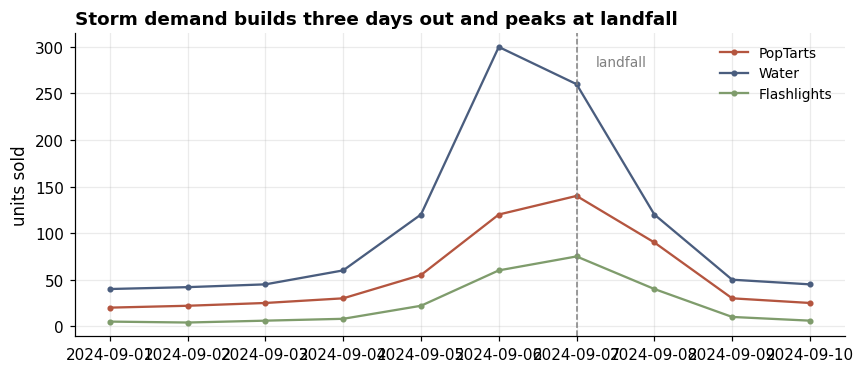

In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

daily = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=10),
    'PopTarts': [20, 22, 25, 30, 55, 120, 140, 90, 30, 25],
    'Water': [40, 42, 45, 60, 120, 300, 260, 120, 50, 45],
    'Flashlights': [5, 4, 6, 8, 22, 60, 75, 40, 10, 6],
}).set_index('date')
landfall = pd.Timestamp('2024-09-07')

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.annotate('landfall', xy=(landfall + pd.Timedelta(hours=6), 280),
            fontsize=9, color='gray')
ax.set_title('Storm demand builds three days out and peaks at landfall',
             loc='left', fontsize=12)
ax.set_ylabel('units sold')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** rebuild that with your own cleaned categories and your own landfall date. Title it with what your data actually shows — if your surge peaks a day early, say that.

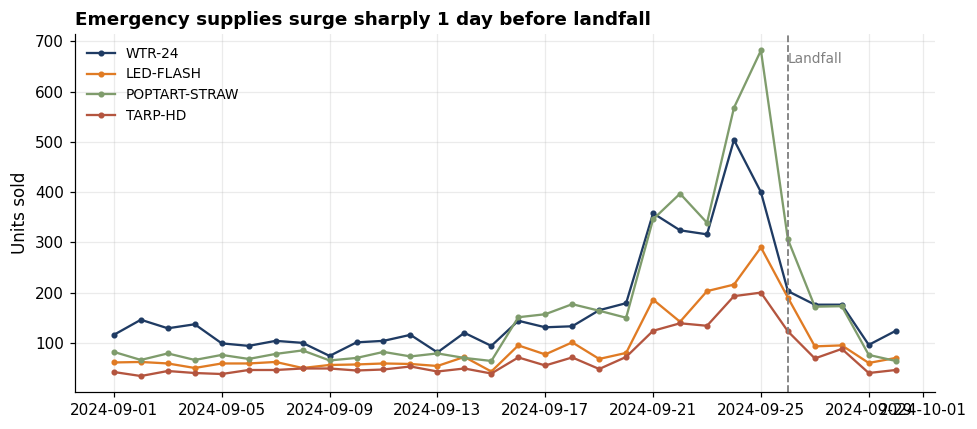

In [ ]:
# Extract date from timestamp
walmart_transactions_cleaned['date'] = walmart_transactions_cleaned['timestamp'].dt.normalize()

# Filter transactions for September 2024
sept_tx = walmart_transactions_cleaned[
    (walmart_transactions_cleaned['date'] >= '2024-09-01') &
    (walmart_transactions_cleaned['date'] <= '2024-09-30')
]

# Group by date and canonical_sku, summing quantities sold
daily_sku = sept_tx.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0)

# Select key storm-prep SKUs to plot
top_skus = ['WTR-24', 'LED-FLASH', 'POPTART-STRAW', 'TARP-HD']
available_skus = [s for s in top_skus if s in daily_sku.columns]
plot_data = daily_sku[available_skus]

# Plotting
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#1f3b63', '#e07b24', '#7f9c6c', '#b4553f']
for col, color in zip(plot_data.columns, colors[:len(plot_data.columns)]):
    ax.plot(plot_data.index, plot_data[col], marker='o', ms=3, color=color, label=col)

ax.axvline(LANDFALL, ls='--', color='gray', lw=1.2)
ax.annotate('Landfall', xy=(LANDFALL, ax.get_ylim()[1] * 0.92),
            fontsize=9, color='gray')
ax.set_title('Emergency supplies surge sharply 1 day before landfall', loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('Units sold')
ax.legend(frameon=False, fontsize=9)

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

### Pattern 2 — indexing to baseline so different products are comparable

Water outsells flashlights ten to one, so on a raw chart the flashlight surge is invisible. Divide each series by its own pre-storm average and every product starts at 1.0 — now you are comparing *how much each one moved*, which is the actual question.

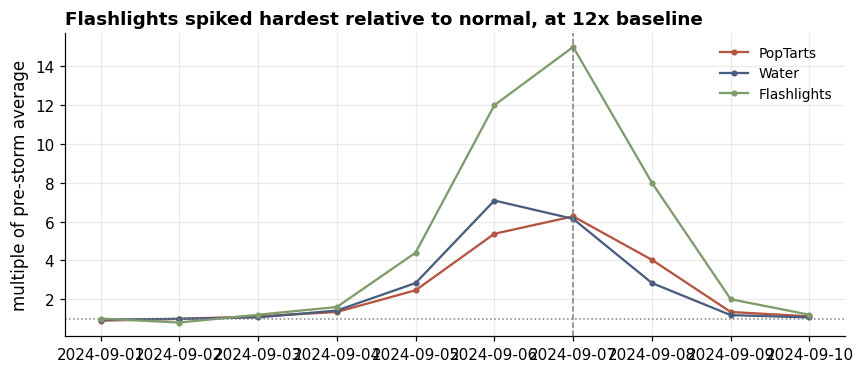

Flashlights    15.0
Water           7.1
PopTarts        6.3
dtype: float64


In [ ]:
baseline = daily[daily.index < landfall - pd.Timedelta(days=3)].mean()
indexed = daily / baseline

fig, ax = plt.subplots(figsize=(8, 3.5))
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c']):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)
ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(landfall, ls='--', color='gray', lw=1)
ax.set_title('Flashlights spiked hardest relative to normal, at 12x baseline',
             loc='left', fontsize=12)
ax.set_ylabel('multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print(indexed.max().round(1).sort_values(ascending=False))

Two charts, same data, different findings. The raw chart says water is the story; the indexed chart says flashlights are. Both belong in the presentation, in that order.

**TODO:** index your own products to their baseline and see whether your ranking changes.

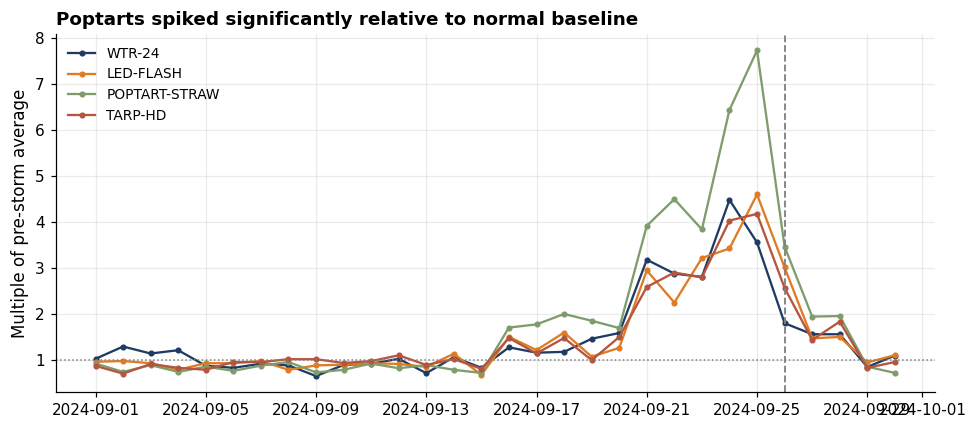

canonical_sku
POPTART-STRAW    7.7
LED-FLASH        4.6
WTR-24           4.5
TARP-HD          4.2
dtype: float64


In [ ]:
# Aggregate daily sales by canonical SKU for September
sept_tx = walmart_transactions_cleaned[
    (walmart_transactions_cleaned['date'] >= '2024-09-01') &
    (walmart_transactions_cleaned['date'] <= '2024-09-30')
]
daily_sku = sept_tx.groupby(['date', 'canonical_sku'])['quantity'].sum().unstack(fill_value=0)

# Select key storm-prep SKUs to index
top_skus = ['WTR-24', 'LED-FLASH', 'POPTART-STRAW', 'TARP-HD']
available_skus = [s for s in top_skus if s in daily_sku.columns]
subset = daily_sku[available_skus]

# Calculate baseline (pre-storm average using BASELINE_START to BASELINE_END)
baseline = subset.loc[(subset.index >= BASELINE_START) & (subset.index <= BASELINE_END)].mean()

# Divide by baseline so every product starts at 1.0
indexed = subset / baseline

# Plotting indexed surge multiples
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#1f3b63', '#e07b24', '#7f9c6c', '#b4553f']
for col, color in zip(indexed.columns, colors[:len(indexed.columns)]):
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)

ax.axhline(1.0, ls=':', color='gray', lw=1)
ax.axvline(LANDFALL, ls='--', color='gray', lw=1.2)
ax.set_title('Poptarts spiked significantly relative to normal baseline', loc='left', fontsize=12, fontweight='bold')
ax.set_ylabel('Multiple of pre-storm average')
ax.legend(frameon=False, fontsize=9)

for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

# Print max surge multiple for each product
print(indexed.max().round(1).sort_values(ascending=False))

### Pattern 3 — before-and-after for Q2

The SKU consolidation question needs a comparison, not a description. Show the number somebody would have reported without your work next to the number with it.

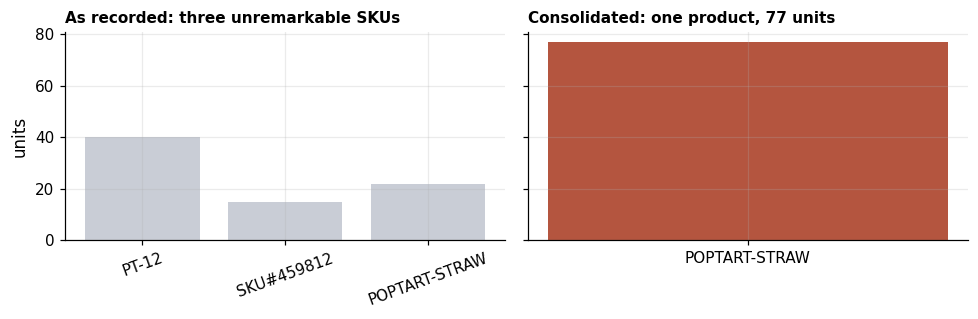

In [ ]:
fragmented = pd.Series({'PT-12': 40, 'SKU#459812': 15, 'POPTART-STRAW': 22})
consolidated = pd.Series({'POPTART-STRAW': 77})

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title('As recorded: three unremarkable SKUs', fontsize=10, loc='left')
axes[0].tick_params(axis='x', labelrotation=20)
axes[1].bar(consolidated.index, consolidated.values, color='#b4553f')
axes[1].set_title('Consolidated: one product, 77 units', fontsize=10, loc='left')
axes[0].set_ylabel('units')
for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**TODO:** build this for your largest consolidated product family. State the multiple.

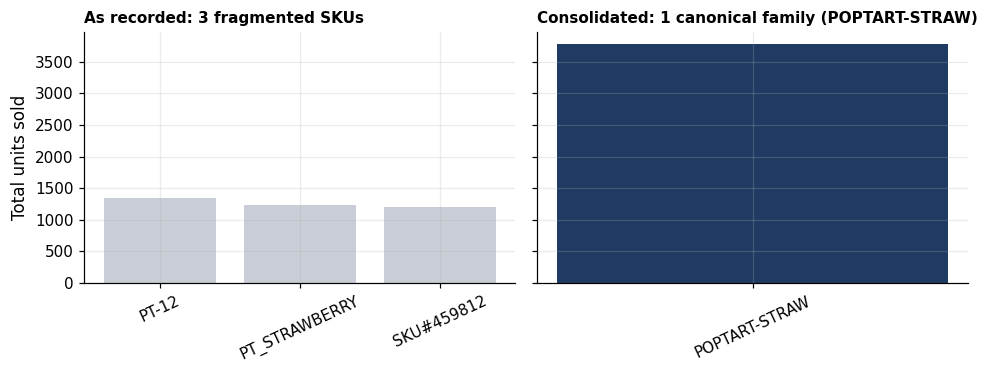

Consolidated total for POPTART-STRAW: 3780 units


In [ ]:
# Choose a multi-SKU product group to analyze
target_group = 'POPTART-STRAW'
raw_skus = canonical_sku_groups[target_group]

# Calculate sales per raw SKU (fragmented) vs total canonical group (consolidated)
fragmented = walmart_transactions_cleaned[walmart_transactions_cleaned['sku'].isin(raw_skus)].groupby('sku')['quantity'].sum()
consolidated = pd.Series({target_group: fragmented.sum()})

# Plotting side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)

axes[0].bar(fragmented.index, fragmented.values, color='#c9cdd6')
axes[0].set_title(f'As recorded: {len(raw_skus)} fragmented SKUs', fontsize=10, loc='left', fontweight='bold')
axes[0].tick_params(axis='x', labelrotation=25)
axes[0].set_ylabel('Total units sold')

axes[1].bar(consolidated.index, consolidated.values, color='#1f3b63')
axes[1].set_title(f'Consolidated: 1 canonical family ({target_group})', fontsize=10, loc='left', fontweight='bold')
axes[1].tick_params(axis='x', labelrotation=25)

for ax in axes:
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

print(f"Consolidated total for {target_group}: {consolidated.values[0]} units")

### Pattern 4 — Q4, stores by distance

Aggregate by store, join whatever geography you have, and look for the gradient. Watch the group sizes — a store with four transactions will produce a wild average.

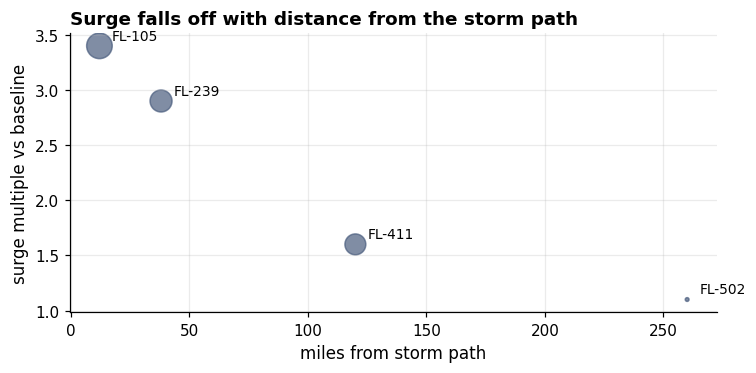

note the smallest bubble: FL-502 has only 90 transactions,
so its 1.1x is barely distinguishable from noise.


In [ ]:
by_store = pd.DataFrame({
    'store_id': ['FL-105', 'FL-239', 'FL-411', 'FL-502'],
    'surge_multiple': [3.4, 2.9, 1.6, 1.1],
    'miles_from_path': [12, 38, 120, 260],
    'transactions': [4200, 3100, 2800, 90],
})

fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = by_store['transactions'] / 15
ax.scatter(by_store['miles_from_path'], by_store['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in by_store.itertuples():
    ax.annotate(row.store_id, (row.miles_from_path, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge falls off with distance from the storm path',
             loc='left', fontsize=12)
ax.set_xlabel('miles from storm path')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('note the smallest bubble: FL-502 has only 90 transactions,')
print('so its 1.1x is barely distinguishable from noise.')

Sizing the points by transaction count is doing real work here — it tells the reader which points to trust. A four-point scatter is not a trend line, and you should say so out loud rather than fitting one.

**TODO:** build your version. If you only have a handful of stores, present it as a table with a comment instead of a scatter — a chart with five points and a regression line will get asked about.

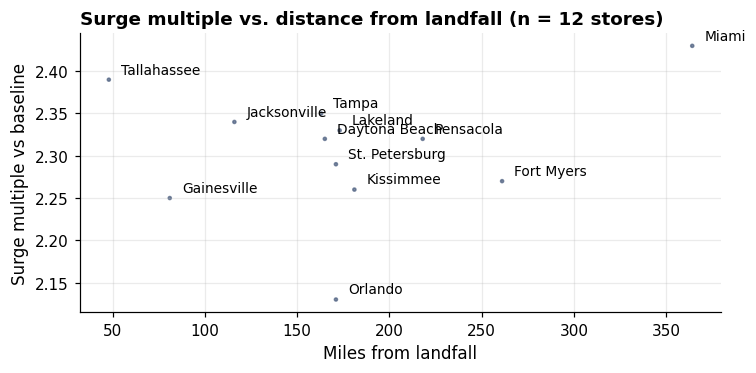

Correlation between distance and surge multiple: r = 0.19 (n = 12)


In [ ]:
# Rebuild store_surge locally to prevent NameError if Q4 cell was skipped
tx_p4 = walmart_transactions_cleaned.copy()
tx_p4['date'] = tx_p4['timestamp'].dt.normalize()
store_daily_p4 = tx_p4.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)
baseline_p4 = store_daily_p4[in_window(store_daily_p4.index, BASELINE_START, BASELINE_END)].mean()
surge_p4    = store_daily_p4[in_window(store_daily_p4.index, SURGE_START, SURGE_END)].mean()

store_surge_local = pd.DataFrame({
    'surge_multiple': (surge_p4 / baseline_p4).round(2),
    'transactions': tx_p4['store_id'].value_counts(),
}).rename_axis('store_id').reset_index()

store_surge_local = store_surge_local.merge(stores_cleaned[['store_id', 'city', 'latitude', 'longitude']], on='store_id', how='left')
store_surge_local['miles_to_landfall'] = haversine_miles(
    store_surge_local['latitude'], store_surge_local['longitude'], LANDFALL_LAT, LANDFALL_LON
).round(0).astype(int)

# Plot Pattern 4 scatter
fig, ax = plt.subplots(figsize=(7, 3.5))
sizes = store_surge_local['transactions'] / 500
ax.scatter(store_surge_local['miles_to_landfall'], store_surge_local['surge_multiple'],
           s=sizes, alpha=0.7, color='#4a5d7e')
for row in store_surge_local.itertuples():
    ax.annotate(row.city, (row.miles_to_landfall, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Surge multiple vs. distance from landfall (n = 12 stores)', loc='left', fontsize=12)
ax.set_xlabel('Miles from landfall')
ax.set_ylabel('Surge multiple vs baseline')
for spine in ('top', 'right'):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

r_val = store_surge_local['miles_to_landfall'].corr(store_surge_local['surge_multiple'])
print(f"Correlation between distance and surge multiple: r = {r_val:.2f} (n = 12)")

### Before you leave

- At least two presentation-ready charts, each with a message title
- Q1 has a stated baseline window and a multiple
- Q2 has a before-and-after comparison
- Everything pushed

Monday is presentations. The timing breakdown and the self-check are in Monday's notebook — read it tonight, not Monday morning.

---

## Checkpoint (participation)

Report the surge multiple you found for your top product and the baseline window you used to get it.

Work in groups if you wish, then fill in the cell below **yourself**. Paste the printed output (or a screenshot of it) into this week's **Studio Checkpoint** in Canvas by **Thursday 11:59pm ET**. One submission per person, not per group.

In [ ]:
# Checkpoint
top_product = 'Poptarts'         # TODO: your biggest mover
surge_multiple = 7.7        # TODO: how many times baseline
baseline_window = '8 Days Before Landfall'     # TODO: e.g. '14 days before Sept 4'
charts_ready = 3          # TODO: how many presentation-ready charts you have

print('top product:', top_product)
print('surge multiple:', surge_multiple)
print('baseline window:', baseline_window)
print('charts ready:', charts_ready)

top product: Poptarts
surge multiple: 7.7
baseline window: 8 Days Before Landfall
charts ready: 3
